In [ ]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm
from l0_data import RAW_ROOT, PROCESSED_ROOT, require_files


In [ ]:
twr_data_dir = str(RAW_ROOT / "Moscow" / "Zve-56m-SNC" / "sonic-fluxes")

df4site = pd.DataFrame()
files = require_files(f'{twr_data_dir}/*.csv')
for file in tqdm (files):
    cur_df = pd.read_csv (file, sep = ';') #, index_col=[0])
    cur_df['datetime'] = pd.to_datetime(cur_df['date'] + ' ' + cur_df['time'], dayfirst=True)
    cur_df = cur_df.set_index('datetime').drop(columns=['date', 'time'])
    df4site = pd.concat((df4site, cur_df))

display (df4site.columns)

df4site = df4site.rename(columns={c: c.split(',')[0] for c in df4site.columns if ',' in c})
df4site['tau'] = - df4site['tau']



,uhor_avg,tavg,uu,vv,ww,tt,uv,uw,vw,wt,u*2,tau,H,u_star,rho
datetime,,,,,,,,,,,,,,,
2020-11-24 13:20:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-11-24 13:30:00,3.43,-0.09,0.4762,0.8332,0.1509,0.0069,0.2533,-0.0219,-0.0352,-0.0052,0.0415,0.0537,-6.75,0.203715,1.293976
2020-11-24 14:00:00,3.30,0.03,0.3817,0.3870,0.1477,0.0147,0.1205,-0.0485,-0.0233,-0.0012,0.0538,0.0695,-1.56,0.231948,1.291822
2020-11-24 14:30:00,3.57,0.06,0.2599,0.2288,0.0979,0.0047,0.0669,-0.0331,0.0041,-0.0026,0.0334,0.0432,-3.38,0.182757,1.293413
2020-11-24 15:00:00,3.68,0.05,0.1631,0.0831,0.0438,0.0041,-0.0020,-0.0185,-0.0034,0.0000,0.0188,0.0243,0.00,0.137113,1.292553
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-02-25 22:00:00,2.04,-5.16,0.0538,0.0440,0.0034,0.0386,0.0082,0.0005,0.0012,-0.0002,0.0013,0.0017,-0.26,0.036056,1.307692
2025-02-25 22:30:00,1.86,-5.47,0.0043,0.0272,0.0003,0.0093,0.0066,-0.0000,-0.0001,0.0001,0.0001,0.0001,0.13,0.010000,1.000000
2025-02-25 23:00:00,2.01,-5.27,0.0352,0.0121,0.0002,0.0142,0.0045,0.0011,0.0008,0.0006,0.0014,0.0018,0.79,0.037417,1.285714


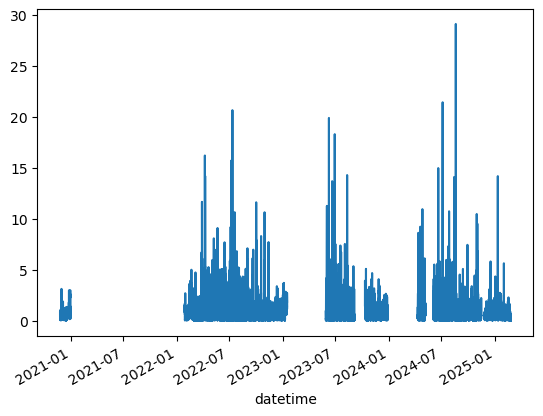

In [3]:
#df4site['rho'] = (746*(1013/760)*100) / (286.7 * (df4site['tavg'] + 273.15))
df4site['u_star'] = np.sqrt(df4site['u*2'])

df4site['rho'] = df4site['tau'] / (df4site['u_star']**2)


# time_arr = pd.date_range(pd.Timestamp(df4site.index.date[0]), pd.Timestamp(df4site.index.date[-1]), freq = '30min') 
# df4site = df4site.resample('30min').last() 
# df4site = df4site.reindex(time_arr)

# df_msu_sel = df_msu[df4site.index[0]:df4site.index[-1]].resample('30min').last().interpolate(method='linear')
# df4site = df4site.merge(df_msu_sel, how = 'left', left_index = True, right_index = True)

# df4site['H'] = df4site['wt'] * df4site['rho'] * 1003
#df4site['tau1'] = df4site['u_star']**2 * df4site['rho'] 
# df4site['wind_vel'] = np.abs(df4site['u_rot'])

# df4sites[str(int (np.round (levels[site]))) + 'm'] = df4site

    #display(files)
df4site['vv'].plot()
df4site

In [4]:
df4site[df4site.index.duplicated()]

,uhor_avg,tavg,uu,vv,ww,tt,uv,uw,vw,wt,u*2,tau,H,u_star,rho
datetime,,,,,,,,,,,,,,,


In [ ]:
export_dir = str(PROCESSED_ROOT / "Moscow")
level = '56m'
os.makedirs(export_dir, exist_ok=True)

df4site['sigma_U'] = np.sqrt(df4site['uu'])
df4site['sigma_V'] = np.sqrt(df4site['vv'])
df4site['sigma_W'] = np.sqrt(df4site['ww'])

df2export = df4site[['H', 'tau', 'u_star', 'tavg', 'rho', 'uhor_avg', 'sigma_U', 'sigma_V', 'sigma_W']]
df2export = df2export.rename(columns = {'H': 'Qh',
                                        'tau': 'Qtau',
                                        'u_star':'Ustar', 
                                        'tavg': 'T_air',
                                        # 'rh': 'RH_air',
                                        # 'ps': 'P_air',
                                        'rho': 'Rho_air',
                                        # 'v':'Wind_V',
                                        # 'u':'Wind_U',
                                        # 'w':'Wind_W',
                                        'uhor_avg':'Wind_vel',                                        
                                        'sigma_U':'Wind_U_std',                                    
                                        'sigma_V':'Wind_V_std', 
                                        'sigma_W':'Wind_W_std'})
df2export.index = df2export.index - pd.Timedelta(hours=3)
df2export.to_csv(export_dir + '/' + 'ZNS_' + level +  '_new.csv')


In [6]:
pd.options.plotting.backend = 'matplotlib'
(df2export['Wind_W_std'] / df2export['Ustar'].where(df2export['Ustar'] > 0, np.nan)).mean()

1.4102390828168228

In [7]:
pd.options.plotting.backend = "plotly"
(df2export['Wind_W_std'] / df2export['Ustar']).plot()